# 06 · Heat doublet and OpenGeoSys export

Single-phase heat transport after the pressure solve: upwind advection and conduction, implicit in temperature.
First a check against the 1D solution of [Ogata & Banks (1961)](https://doi.org/10.3133/pp411A), then a cold-water
doublet injecting 30 °C water into an 80 °C reservoir for 30 years, exported as a VTU mesh for OpenGeoSys.
Properties are illustrative.

## Setup

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## 1D check against Ogata–Banks

In [2]:
from subsurfix import _native as nat
from math import erfc, exp, sqrt
n, dx, k, phi = 1000, 0.05, 1e-12, 0.2
m = nat.FlowModel.from_regular([0, 0, 0], [dx, 1, 1], [n, 1, 1], np.full((n, 3), k), np.full(n, phi))
props = dict(rho_fluid=1000.0, cp_fluid=4180.0, rho_rock=2650.0, cp_rock=900.0, cond_fluid=0.6, cond_rock=2.5)
cap = phi * 1000 * 4180 + (1 - phi) * 2650 * 900
lam = phi * 0.6 + (1 - phi) * 2.5
u = 1e-6
v, D = u * 1000 * 4180 / cap, lam / cap
t_end = 20.0 / v
wells = [{"name": "I", "kind": "injector", "cells": [0], "rate": u, "radius": 0.1}]
fixed = [nat.FixedPressure(n - 1, m.boundary_trans(n - 1, 0), 1e7, pressure_unit="Pa")]
inlet = [{"cell": 0, "conductance": lam * m.boundary_geom(0, 0), "temperature": 1.0}]
r = m.run_heat(np.full(n, 1e3), wells, [1.0], np.zeros(n), [t_end], fixed=fixed, fixed_temp=[0.0],
               fixed_t=inlet, props=props, dt_max=1e4)
x = (np.arange(n) + 0.5) * dx
s = 2 * sqrt(D * t_end)
ob = np.array([0.5 * (erfc((xi - v * t_end) / s) + exp(v * xi / D) * erfc((xi + v * t_end) / s)) if v * xi / D < 700 else 0.0 for xi in x])
err = np.abs(r["temperature"][0] - ob).max()
print(f"max abs error {err:.4f} (normalised temperature)")

max abs error 0.0086 (normalised temperature)


## Doublet
Edit the rate, temperatures and permeability here.

In [3]:
nx = ny = 30; cell = (25.0, 25.0, 20.0)
N = nx * ny
rng = np.random.default_rng(7)
kmd = np.exp(rng.normal(np.log(300), 0.5, N))
dbl = nat.FlowModel.from_regular([0, 0, 2000], cell, [nx, ny, 1], np.column_stack([kmd * 9.869e-16] * 3), np.full(N, 0.2))
cid = lambda i, j: i + nx * j
wells = [{"name": "INJ", "kind": "injector", "cells": [cid(5, 5)], "rate": 0.02, "radius": 0.1},
         {"name": "PROD", "kind": "producer", "cells": [cid(24, 24)], "bhp": 2e7, "radius": 0.1}]
yr = 3.156e7
years = [1, 2, 5, 10, 15, 20, 25, 30]
res = dbl.run_heat(np.full(N, 1 / 5e-4), wells, [30.0, 0.0], np.full(N, 80.0), [y * yr for y in years], props=props, dt_max=0.05 * yr)
T = res["temperature"]
bal = np.abs(np.array(res["energy_change"]) - np.array(res["energy_in"])) / np.abs(res["energy_in"])
print("energy balance error max", f"{bal.max():.1e}")
print("producer temperature (degC):", dict(zip(years, T[:, cid(24, 24)].round(2))))

energy balance error max 1.1e-14
producer temperature (degC): {1: np.float64(80.0), 2: np.float64(80.0), 5: np.float64(78.58), 10: np.float64(51.61), 15: np.float64(40.45), 20: np.float64(35.6), 25: np.float64(33.06), 30: np.float64(31.62)}


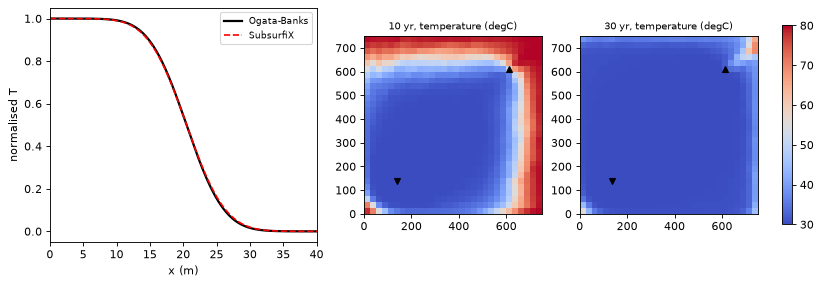

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
axs[0].plot(x, ob, "k-", lw=2, label="Ogata-Banks"); axs[0].plot(x, r["temperature"][0], "r--", label="SubsurfiX")
axs[0].set_xlim(0, 40); axs[0].set_xlabel("x (m)"); axs[0].set_ylabel("normalised T"); axs[0].legend(fontsize=8)
ext = [0, nx * cell[0], 0, ny * cell[1]]
for ax, it in zip(axs[1:], (3, 7)):
    im = ax.imshow(T[it].reshape(ny, nx), origin="lower", extent=ext, vmin=30, vmax=80, cmap="coolwarm")
    ax.plot(5.5 * 25, 5.5 * 25, "kv"); ax.plot(24.5 * 25, 24.5 * 25, "k^")
    ax.set_title(f"{years[it]} yr, temperature (degC)", fontsize=9)
fig.colorbar(im, ax=axs[1:], shrink=0.85); save(fig, "06_heat_doublet.png")

## Export to OpenGeoSys
Writes the mesh with the model properties, the input permeability and the final temperature as cell data. Open it in ParaView or
use it as the mesh of an OpenGeoSys project.

In [5]:
info = dbl.export_ogs(OUT / "doublet.vtu", cell_data={"permeability_mD": kmd, "temperature_30yr": np.asarray(T[-1])})
print(info)

{'n_cells': 900, 'n_nodes': 1922}
